In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_curve
from sklearn.metrics import confusion_matrix
from sklearn.metrics import log_loss
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score)
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_graphviz
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_predict, StratifiedKFold, KFold
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.svm import LinearSVC
from sklearn.ensemble import BaggingClassifier

In [2]:
# train 데이터 확인인
train=pd.read_csv("train_set .csv")
train.isnull().sum()
train.describe()

,Age,Nodule_Size,TSH_Result,T4_Result,T3_Result,Cancer
count,77159.000000,77159.000000,77159.000000,77159.000000,77159.000000,77159.000000
mean,50.849596,2.506308,5.055568,8.249941,2.003840,0.119973
std,21.622391,1.440639,2.859620,2.166917,0.866830,0.324932
min,14.000000,0.000000,0.100000,4.500000,0.500000,0.000000
25%,32.000000,1.270332,2.584197,6.372989,1.254836,0.000000
50%,51.000000,2.510794,5.062922,8.241484,2.002187,0.000000
75%,70.000000,3.750685,7.535332,10.132123,2.757413,0.000000
max,88.000000,5.000000,10.000000,12.000000,3.500000,1.000000


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77159 entries, 0 to 77158
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 77159 non-null  object 
 1   Age                77159 non-null  int64  
 2   Gender             77159 non-null  object 
 3   Country            77159 non-null  object 
 4   Race               77159 non-null  object 
 5   Family_Background  77159 non-null  object 
 6   Radiation_History  77159 non-null  object 
 7   Iodine_Deficiency  77159 non-null  object 
 8   Smoke              77159 non-null  object 
 9   Weight_Risk        77159 non-null  object 
 10  Diabetes           77159 non-null  object 
 11  Nodule_Size        77159 non-null  float64
 12  TSH_Result         77159 non-null  float64
 13  T4_Result          77159 non-null  float64
 14  T3_Result          77159 non-null  float64
 15  Cancer             77159 non-null  int64  
dtypes: float64(4), int64(2

In [4]:
# 나라 종류가 너무 많아 one-hot encoding 할 경우 복잡할 것 대비해서 대륙별 구성
def map_country(country):
    asia = ['CHN', 'IND', 'JPN', 'KOR']
    europe = ['DEU', 'GBR', 'RUS']
    americas = ['USA', 'BRA']
    africa = ['NGA']
    
    if country in asia:
        return 'Asia'
    elif country in europe:
        return 'Europe'
    elif country in americas:
        return 'Americas'
    else:
        return 'Africa'
train['Region'] = train['Country'].apply(map_country)
train.head()

,ID,Age,Gender,Country,Race,Family_Background,Radiation_History,Iodine_Deficiency,Smoke,Weight_Risk,Diabetes,Nodule_Size,TSH_Result,T4_Result,T3_Result,Cancer,Region
0,TRAIN_00001,45,M,JPN,HSP,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,1.230754,9.584328,6.601513,3.328953,0,Asia
1,TRAIN_00002,86,M,NGA,AFR,Negative,Unexposed,Deficient,Non-Smoker,Obese,Yes,1.090337,1.652765,7.675531,2.506364,0,Africa
2,TRAIN_00003,73,F,IND,CAU,Positive,Exposed,Sufficient,Smoker,Not Obese,No,2.870067,8.514824,4.516257,2.248125,0,Asia
3,TRAIN_00004,37,F,KOR,HSP,Negative,Unexposed,Deficient,Non-Smoker,Not Obese,No,3.670968,1.772640,9.844377,1.864518,0,Asia
4,TRAIN_00005,33,F,GBR,AFR,Positive,Unexposed,Sufficient,Smoker,Not Obese,Yes,4.450866,9.922852,6.854556,2.388870,0,Europe


In [5]:
train["T3_T4_ratio"] = train["T3_Result"] / (train["T4_Result"] + 1e-5)
train["TSH_Age_mul"] = train["TSH_Result"] * train["Age"]

In [6]:
# 필요없다 판단된 id, country 컬럼 제거
train=train.drop(columns=['ID', 'Country']) 

In [7]:
# train data에 대하여 train과 test로 나누어 구성
tr_1=train.copy(deep=True)
tr, te = train_test_split(tr_1, test_size=0.2, random_state=42)
tr_x=tr.drop(columns='Cancer')
tr_y=tr['Cancer']
te_x=te.drop(columns='Cancer')
te_y=te['Cancer']
print(tr_y.value_counts())

Cancer
0    54348
1     7379
Name: count, dtype: int64


In [8]:
print(len(tr_x), len(te_x))

61727 15432


In [9]:
# 각 컬럼 재확인
unique_counts=tr_x.nunique()
print(unique_counts)

Age                     75
Gender                   2
Race                     5
Family_Background        2
Radiation_History        2
Iodine_Deficiency        2
Smoke                    2
Weight_Risk              2
Diabetes                 2
Nodule_Size            501
TSH_Result           61404
T4_Result            61355
T3_Result            60729
Region                   4
T3_T4_ratio          61727
TSH_Age_mul          61697
dtype: int64


In [10]:
# 연속형 컬럼과 범주형 컬럼, 목표 컬럼을 구분
con_cols=["Age","Nodule_Size","TSH_Result","T4_Result","T3_Result","T3_T4_ratio","TSH_Age_mul"]
cat_cols=["Gender", "Race","Family_Background", "Radiation_History","Iodine_Deficiency","Smoke","Weight_Risk","Diabetes","Region"]
target_col=["Cancer"]

In [11]:
# train에 사용될 데이터들의 분포 확인
tr_x[con_cols].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Age,61727.0,50.882434,21.641849,14.000000,32.000000,51.000000,70.000000,88.000000
Nodule_Size,61727.0,2.507115,1.439575,0.000000,1.270332,2.510794,3.750685,5.000000
TSH_Result,61727.0,5.050792,2.858279,0.100000,2.580614,5.059020,7.525168,10.000000
T4_Result,61727.0,8.256394,2.166267,4.500000,6.379298,8.252743,10.138052,12.000000
T3_Result,61727.0,2.003949,0.866394,0.500000,1.257424,2.003315,2.757002,3.500000
T3_T4_ratio,61727.0,0.261858,0.139616,0.041845,0.152454,0.242367,0.341787,0.777054
TSH_Age_mul,61727.0,256.853501,192.213113,1.500000,102.287001,210.868500,375.855906,880.000000


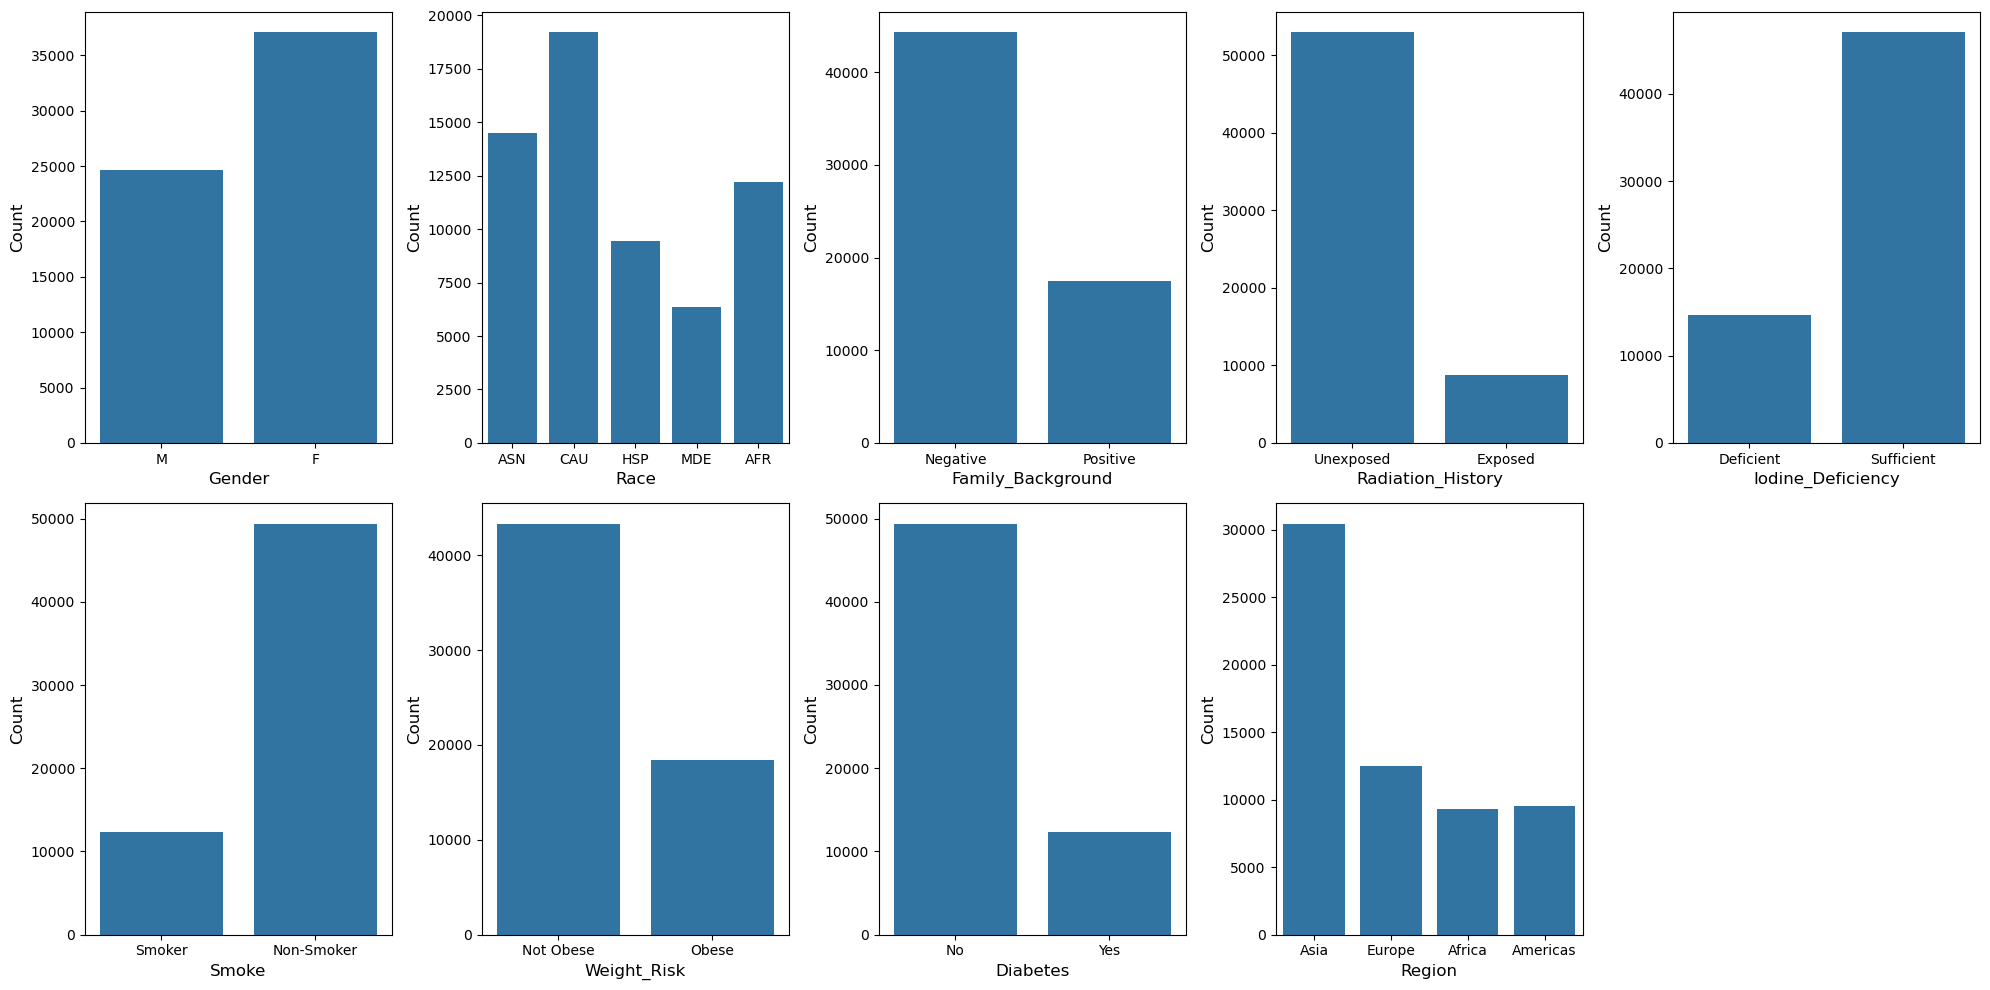

In [12]:
plt.figure(figsize=(20, 10))
for i, feature in enumerate(cat_cols,1):
    plt.subplot(2,5,i)
    sns.countplot(x=feature, data=tr_x)
    plt.ylabel("Count", fontsize=12)
    plt.xlabel(feature, fontsize=12)
    plt.tight_layout()

<Axes: xlabel='Cancer', ylabel='count'>

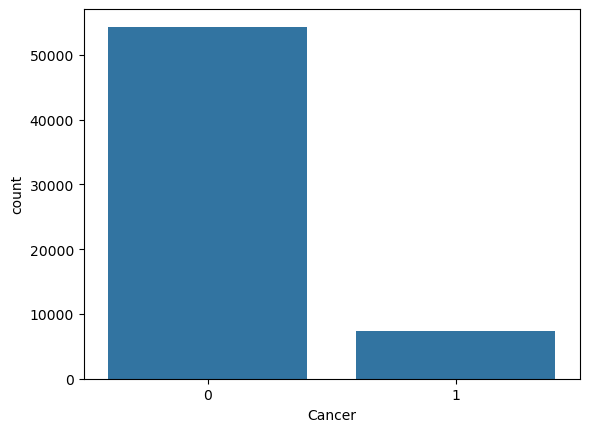

In [13]:
sns.countplot(x=tr_y)

In [14]:
#sns.pairplot(tr_1[con_cols+['Cancer']], hue='Cancer')
#plt.show()

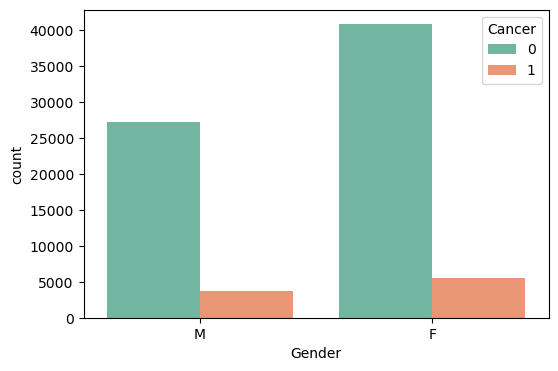

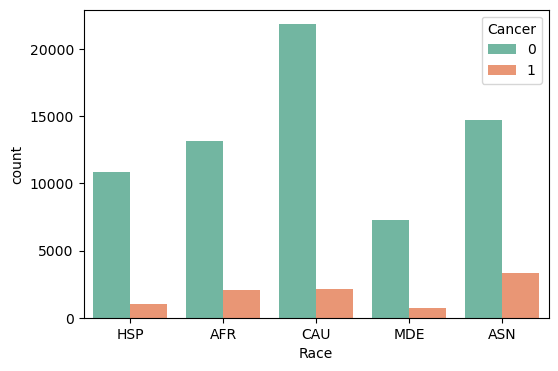

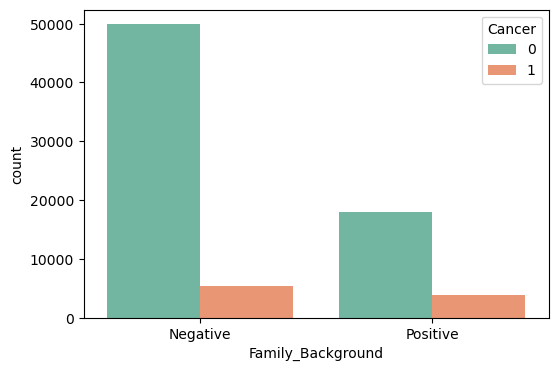

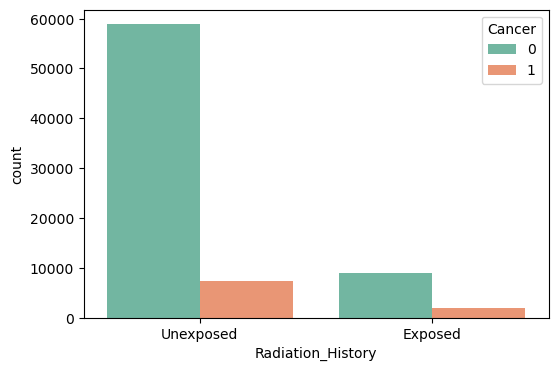

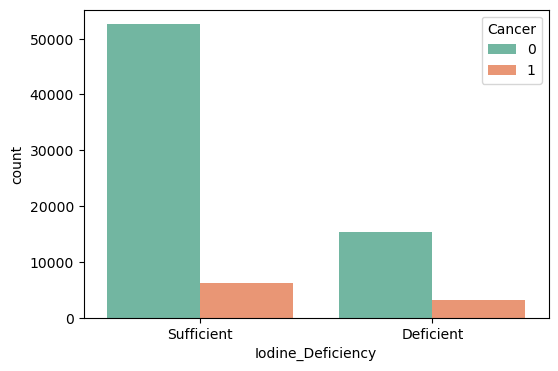

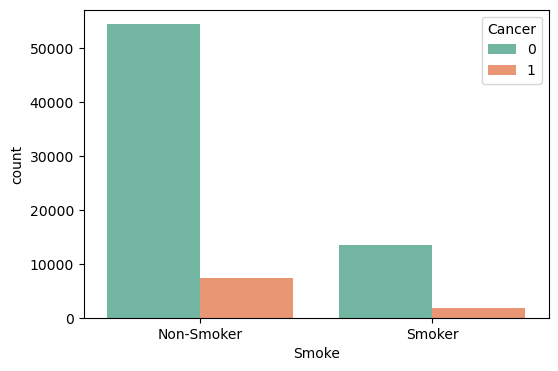

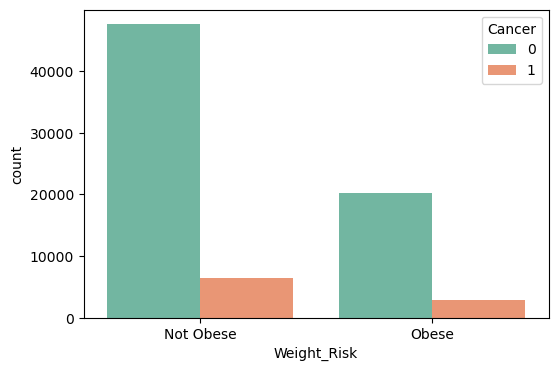

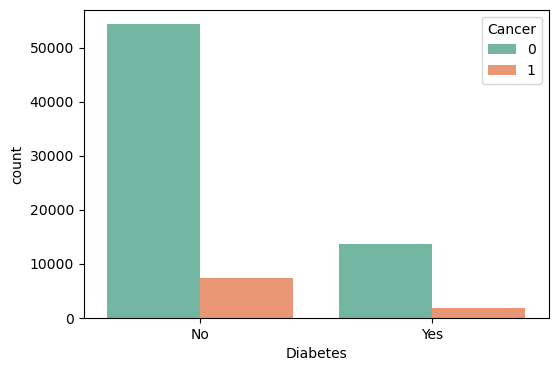

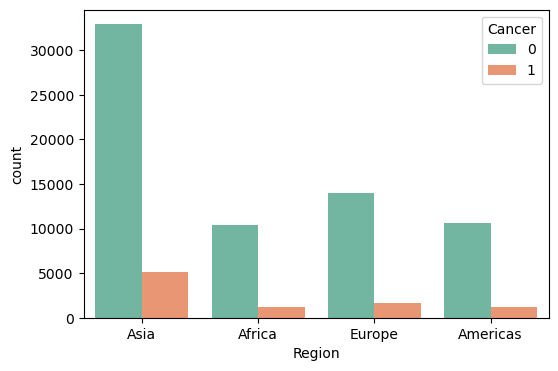

In [15]:
for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Cancer', data=tr_1, palette='Set2')
    plt.show()

In [16]:
# 모두 동일한 방식으로 인코딩 진행
full_x = pd.concat([tr_x, te_x], axis=0)
full_x_encoded = pd.get_dummies(full_x, columns=cat_cols, drop_first=True)
tr_len = len(tr_x)
tr_x = full_x_encoded.iloc[:tr_len, :].copy()
te_x = full_x_encoded.iloc[tr_len:, :].copy()

In [17]:
print("The shape of tr_x is ", tr_x.shape)
print("The shape of te_x is ", te_x.shape)

The shape of tr_x is  (61727, 21)
The shape of te_x is  (15432, 21)


In [18]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

lr_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[LR] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    # SMOTEENN
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    # 스케일링
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정 Logistic Regression
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(x_res_scaled, y_res)

    lr_pred = model.predict_proba(x_test_scaled)[:, 1]
    lr_preds.append(lr_pred)

# 평균 예측 결과
avg_lr_pred = np.mean(lr_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_lr_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

# 예측 및 평가
y_pred_lr = (avg_lr_pred > 0.4).astype(int)
print(f"[LR] F1-score: {f1_score(te_y, y_pred_lr, average='weighted'):.4f}")
print("[LR] Confusion matrix:\n", confusion_matrix(te_y, y_pred_lr))

[LR] Fold 1/5
[LR] Fold 2/5
[LR] Fold 3/5
[LR] Fold 4/5
[LR] Fold 5/5
[LR] F1-score: 0.7302
[LR] Confusion matrix:
 [[9807 3747]
 [1158  720]]


In [19]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
knn_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[KNN] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정 KNN
    model = KNeighborsClassifier()
    model.fit(x_res_scaled, y_res)

    knn_pred = model.predict_proba(x_test_scaled)[:, 1]
    knn_preds.append(knn_pred)

# 평균 예측 결과
avg_knn_pred = np.mean(knn_preds, axis=0)

# 최적 threshold 계산
precision, recall, thresholds = precision_recall_curve(te_y, avg_knn_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

# 예측 및 평가
y_pred_knn = (avg_knn_pred > 0.4).astype(int)
print(f"[KNN] F1-score: {f1_score(te_y, y_pred_knn, average='weighted'):.4f}")
print("[KNN] Confusion matrix:\n", confusion_matrix(te_y, y_pred_knn))

[KNN] Fold 1/5
[KNN] Fold 2/5
[KNN] Fold 3/5
[KNN] Fold 4/5
[KNN] Fold 5/5
[KNN] F1-score: 0.6885
[KNN] Confusion matrix:
 [[8508 5046]
 [ 764 1114]]


In [20]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

dt_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[DT] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정으로 DecisionTreeClassifier 사용
    model = DecisionTreeClassifier(random_state=42)
    model.fit(x_res_scaled, y_res)

    dt_pred = model.predict_proba(x_test_scaled)[:, 1]
    dt_preds.append(dt_pred)

avg_dt_pred = np.mean(dt_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_dt_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

y_pred_dt = (avg_dt_pred > 0.4).astype(int)
print(f"[DT] F1-score: {f1_score(te_y, y_pred_dt, average='weighted'):.4f}")
print("[DT] Confusion matrix:\n", confusion_matrix(te_y, y_pred_dt))

[DT] Fold 1/5
[DT] Fold 2/5
[DT] Fold 3/5
[DT] Fold 4/5
[DT] Fold 5/5
[DT] F1-score: 0.7785
[DT] Confusion matrix:
 [[10779  2775]
 [ 1112   766]]


In [21]:
# SVM
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

svm_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[SVM] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정으로 SVM 모델 사용
    base_svm = LinearSVC(max_iter=10000, random_state=42)
    calibrated_svm = CalibratedClassifierCV(base_svm, cv=3)
    calibrated_svm.fit(x_res_scaled, y_res)

    svm_pred = calibrated_svm.predict_proba(x_test_scaled)[:, 1]
    svm_preds.append(svm_pred)

avg_svm_pred = np.mean(svm_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_svm_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
y_pred_svm = (avg_svm_pred > 0.4).astype(int)
print(f"[SVM] F1-score: {f1_score(te_y, y_pred_svm, average='weighted'):.4f}")
print("[SVM] Confusion matrix:\n", confusion_matrix(te_y, y_pred_svm))

[SVM] Fold 1/5
[SVM] Fold 2/5
[SVM] Fold 3/5
[SVM] Fold 4/5
[SVM] Fold 5/5
[SVM] F1-score: 0.6117
[SVM] Confusion matrix:
 [[7164 6390]
 [ 823 1055]]


In [22]:
# RT
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

rf_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[RF] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)
    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(x_res_scaled, y_res)

    rf_pred = rf_model.predict_proba(x_test_scaled)[:, 1]
    rf_preds.append(rf_pred)

avg_rf_pred = np.mean(rf_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_rf_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

y_pred_rf = (avg_rf_pred > 0.4).astype(int)
print(f"[RF] F1-score: {f1_score(te_y, y_pred_rf, average='weighted'):.4f}")
print("[RF] Confusion matrix:\n", confusion_matrix(te_y, y_pred_rf))

[RF] Fold 1/5
[RF] Fold 2/5
[RF] Fold 3/5
[RF] Fold 4/5
[RF] Fold 5/5
[RF] F1-score: 0.7450
[RF] Confusion matrix:
 [[9805 3749]
 [ 917  961]]


In [23]:
# DT
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
bagging_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[Bagging-DT] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)
    base_dt = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42
    )
    bagging = BaggingClassifier(
    estimator=base_dt,  
    n_estimators=50,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)
    bagging.fit(x_res_scaled, y_res)
    pred = bagging.predict_proba(x_test_scaled)[:, 1]
    bagging_preds.append(pred)
avg_bagging_pred = np.mean(bagging_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_bagging_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"[Bagging-DT] Best threshold: {best_thresh:.3f}")
y_pred_bagging = (avg_bagging_pred > best_thresh).astype(int)
print(f"[Bagging-DT] F1-score: {f1_score(te_y, y_pred_bagging, average='weighted'):.4f}")
print("[Bagging-DT] Confusion matrix:\n", confusion_matrix(te_y, y_pred_bagging))

[Bagging-DT] Fold 1/5
[Bagging-DT] Fold 2/5
[Bagging-DT] Fold 3/5
[Bagging-DT] Fold 4/5
[Bagging-DT] Fold 5/5
[Bagging-DT] Best threshold: 0.537
[Bagging-DT] F1-score: 0.8500
[Bagging-DT] Confusion matrix:
 [[12795   759]
 [ 1372   506]]


In [24]:
# Random Forest
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
param_grid_rf = {
    'n_estimators': [100, 150],
    'max_depth': [5, 10],
    'min_samples_leaf': [1, 3],
    'class_weight': ['balanced']
}
rf_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[RF] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=3, scoring='f1_weighted', n_jobs=-1)
    grid.fit(x_res_scaled, y_res)

    best_rf = grid.best_estimator_
    rf_pred = best_rf.predict_proba(x_test_scaled)[:, 1]
    rf_preds.append(rf_pred)

avg_rf_pred = np.mean(rf_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_rf_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"[RF] Best threshold: {best_thresh:.3f}")

y_pred_rf = (avg_rf_pred > best_thresh).astype(int)
print(f"[RF] F1-score: {f1_score(te_y, y_pred_rf, average='weighted'):.4f}")
print("[RF] Confusion matrix:\n", confusion_matrix(te_y, y_pred_rf))

[RF] Fold 1/5
[RF] Fold 2/5
[RF] Fold 3/5
[RF] Fold 4/5
[RF] Fold 5/5
[RF] Best threshold: 0.597
[RF] F1-score: 0.8546
[RF] Confusion matrix:
 [[12979   575]
 [ 1413   465]]


In [25]:
dt = DecisionTreeClassifier(random_state=42)
feature_names = tr_x.columns
kf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
importances = []
for train_index, val_index in kf.split(tr_x, tr_y):
    X_train, X_val = tr_x.iloc[train_index], tr_x.iloc[val_index]
    y_train, y_val = tr_y.iloc[train_index], tr_y.iloc[val_index]
    dt.fit(X_train, y_train)
    importances.append(dt.feature_importances_)
mean_importance = np.mean(importances, axis=0)
feat_imp = pd.Series(mean_importance, index=feature_names).sort_values(ascending=False)
print(feat_imp)

T4_Result                       0.120094
Nodule_Size                     0.119722
TSH_Result                      0.115741
T3_Result                       0.111638
TSH_Age_mul                     0.107847
T3_T4_ratio                     0.105376
Age                             0.078910
Family_Background_Positive      0.077299
Race_MDE                        0.020507
Region_Asia                     0.017422
Race_HSP                        0.013705
Gender_M                        0.013458
Race_CAU                        0.013376
Weight_Risk_Obese               0.012682
Race_ASN                        0.012612
Smoke_Smoker                    0.011449
Diabetes_Yes                    0.011371
Radiation_History_Unexposed     0.010691
Iodine_Deficiency_Sufficient    0.010003
Region_Americas                 0.008071
Region_Europe                   0.008026
dtype: float64


In [26]:
train=train[["TSH_Result","T3_Result","T4_Result","Nodule_Size","Age","Cancer","Family_Background","Region","Race","TSH_Age_mul","T3_T4_ratio"]] 
tr_2=train.copy(deep=True)
tr, te = train_test_split(tr_2, test_size=0.2, random_state=42)
tr_x=tr.drop(columns='Cancer')
tr_y=tr['Cancer']
te_x=te.drop(columns='Cancer')
te_y=te['Cancer']
con_cols=["Age","Nodule_Size","TSH_Result","T4_Result","T3_Result","TSH_Age_mul","T3_T4_ratio"]
cat_cols=["Family_Background","Region","Race"]
full_x = pd.concat([tr_x, te_x], axis=0)
full_x_encoded = pd.get_dummies(full_x, columns=cat_cols, drop_first=True)
tr_len = len(tr_x)
tr_x = full_x_encoded.iloc[:tr_len, :].copy()
te_x = full_x_encoded.iloc[tr_len:, :].copy()

In [27]:
# LR
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

lr_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[LR] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    # SMOTEENN
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    # 스케일링
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정 Logistic Regression
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(x_res_scaled, y_res)

    lr_pred = model.predict_proba(x_test_scaled)[:, 1]
    lr_preds.append(lr_pred)

# 평균 예측 결과
avg_lr_pred = np.mean(lr_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_lr_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

# 예측 및 평가
y_pred_lr = (avg_lr_pred > 0.4).astype(int)
print(f"[LR] F1-score: {f1_score(te_y, y_pred_lr, average='weighted'):.4f}")
print("[LR] Confusion matrix:\n", confusion_matrix(te_y, y_pred_lr))

[LR] Fold 1/5
[LR] Fold 2/5
[LR] Fold 3/5
[LR] Fold 4/5
[LR] Fold 5/5
[LR] F1-score: 0.7200
[LR] Confusion matrix:
 [[9563 3991]
 [1136  742]]


In [28]:
# KNN
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
knn_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[KNN] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정 KNN
    model = KNeighborsClassifier()
    model.fit(x_res_scaled, y_res)

    knn_pred = model.predict_proba(x_test_scaled)[:, 1]
    knn_preds.append(knn_pred)

# 평균 예측 결과
avg_knn_pred = np.mean(knn_preds, axis=0)

# 최적 threshold 계산
precision, recall, thresholds = precision_recall_curve(te_y, avg_knn_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

# 예측 및 평가
y_pred_knn = (avg_knn_pred > 0.4).astype(int)
print(f"[KNN] F1-score: {f1_score(te_y, y_pred_knn, average='weighted'):.4f}")
print("[KNN] Confusion matrix:\n", confusion_matrix(te_y, y_pred_knn))

[KNN] Fold 1/5
[KNN] Fold 2/5
[KNN] Fold 3/5
[KNN] Fold 4/5
[KNN] Fold 5/5
[KNN] F1-score: 0.6855
[KNN] Confusion matrix:
 [[8580 4974]
 [ 886  992]]


In [29]:
# DT
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

dt_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[DT] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정으로 DecisionTreeClassifier 사용
    model = DecisionTreeClassifier(random_state=42)
    model.fit(x_res_scaled, y_res)

    dt_pred = model.predict_proba(x_test_scaled)[:, 1]
    dt_preds.append(dt_pred)

avg_dt_pred = np.mean(dt_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_dt_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

y_pred_dt = (avg_dt_pred > 0.4).astype(int)
print(f"[DT] F1-score: {f1_score(te_y, y_pred_dt, average='weighted'):.4f}")
print("[DT] Confusion matrix:\n", confusion_matrix(te_y, y_pred_dt))

[DT] Fold 1/5
[DT] Fold 2/5
[DT] Fold 3/5
[DT] Fold 4/5
[DT] Fold 5/5
[DT] F1-score: 0.7734
[DT] Confusion matrix:
 [[10805  2749]
 [ 1204   674]]


In [30]:
# SVM
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

svm_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[SVM] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    # 기본 설정으로 SVM 모델 사용
    base_svm = LinearSVC(max_iter=10000, random_state=42)
    calibrated_svm = CalibratedClassifierCV(base_svm, cv=3)
    calibrated_svm.fit(x_res_scaled, y_res)

    svm_pred = calibrated_svm.predict_proba(x_test_scaled)[:, 1]
    svm_preds.append(svm_pred)

avg_svm_pred = np.mean(svm_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_svm_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
y_pred_svm = (avg_svm_pred > 0.4).astype(int)
print(f"[SVM] F1-score: {f1_score(te_y, y_pred_svm, average='weighted'):.4f}")
print("[SVM] Confusion matrix:\n", confusion_matrix(te_y, y_pred_svm))

[SVM] Fold 1/5
[SVM] Fold 2/5
[SVM] Fold 3/5
[SVM] Fold 4/5
[SVM] Fold 5/5
[SVM] F1-score: 0.5586
[SVM] Confusion matrix:
 [[6176 7378]
 [ 697 1181]]


In [31]:
# RT
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

rf_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[RF] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)
    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(x_res_scaled, y_res)

    rf_pred = rf_model.predict_proba(x_test_scaled)[:, 1]
    rf_preds.append(rf_pred)

avg_rf_pred = np.mean(rf_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_rf_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

y_pred_rf = (avg_rf_pred > 0.4).astype(int)
print(f"[RF] F1-score: {f1_score(te_y, y_pred_rf, average='weighted'):.4f}")
print("[RF] Confusion matrix:\n", confusion_matrix(te_y, y_pred_rf))

[RF] Fold 1/5
[RF] Fold 2/5
[RF] Fold 3/5
[RF] Fold 4/5
[RF] Fold 5/5
[RF] F1-score: 0.7460
[RF] Confusion matrix:
 [[9993 3561]
 [1047  831]]


In [32]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
bagging_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[Bagging-DT] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)
    base_dt = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42
    )
    bagging = BaggingClassifier(
    estimator=base_dt,  
    n_estimators=50,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)
    bagging.fit(x_res_scaled, y_res)
    pred = bagging.predict_proba(x_test_scaled)[:, 1]
    bagging_preds.append(pred)
avg_bagging_pred = np.mean(bagging_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_bagging_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"[Bagging-DT] Best threshold: {best_thresh:.3f}")
y_pred_bagging = (avg_bagging_pred > best_thresh).astype(int)
print(f"[Bagging-DT] F1-score: {f1_score(te_y, y_pred_bagging, average='weighted'):.4f}")
print("[Bagging-DT] Confusion matrix:\n", confusion_matrix(te_y, y_pred_bagging))

[Bagging-DT] Fold 1/5
[Bagging-DT] Fold 2/5
[Bagging-DT] Fold 3/5
[Bagging-DT] Fold 4/5
[Bagging-DT] Fold 5/5
[Bagging-DT] Best threshold: 0.516
[Bagging-DT] F1-score: 0.8611
[Bagging-DT] Confusion matrix:
 [[13172   382]
 [ 1439   439]]


In [ ]:
# Random Forest
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
param_grid_rf = {
    'n_estimators': [100, 150],
    'max_depth': [5, 10],
    'min_samples_leaf': [1, 3],
    'class_weight': ['balanced']
}
rf_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[RF] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]

    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)

    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)

    grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=3, scoring='f1_weighted', n_jobs=-1)
    grid.fit(x_res_scaled, y_res)

    best_rf = grid.best_estimator_
    rf_pred = best_rf.predict_proba(x_test_scaled)[:, 1]
    rf_preds.append(rf_pred)

avg_rf_pred = np.mean(rf_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_rf_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"[RF] Best threshold: {best_thresh:.3f}")

y_pred_rf = (avg_rf_pred > best_thresh).astype(int)
print(f"[RF] F1-score: {f1_score(te_y, y_pred_rf, average='weighted'):.4f}")
print("[RF] Confusion matrix:\n", confusion_matrix(te_y, y_pred_rf))    

[RF] Fold 1/5
[RF] Fold 2/5
[RF] Fold 3/5
[RF] Fold 4/5
[RF] Fold 5/5
[RF] Best threshold: 0.567
[RF] F1-score: 0.8605
[RF] Confusion matrix:
 [[13153   401]
 [ 1436   442]]


In [ ]:
train=train[["TSH_Result","T3_Result","T4_Result","Nodule_Size","Age","Cancer","Family_Background","Region","Race","TSH_Age_mul","T3_T4_ratio"]] 
tr_2=train.copy(deep=True)
tr, te = train_test_split(tr_2, test_size=0.2, random_state=42)
tr_x=tr.drop(columns='Cancer')
tr_y=tr['Cancer']
te_x=te.drop(columns='Cancer')
te_y=te['Cancer']
con_cols=["Age","Nodule_Size","TSH_Result","T4_Result","T3_Result","TSH_Age_mul","T3_T4_ratio"]
cat_cols=["Family_Background","Region","Race"]
full_x = pd.concat([tr_x, te_x], axis=0)
full_x_encoded = pd.get_dummies(full_x, columns=cat_cols, drop_first=True)
tr_len = len(tr_x)
tr_x = full_x_encoded.iloc[:tr_len, :].copy()
te_x = full_x_encoded.iloc[tr_len:, :].copy()

In [ ]:
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
bagging_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    print(f"[Bagging-DT] Fold {fold + 1}/{n_folds}")
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    x_test_scaled = scaler.transform(te_x)
    base_dt = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42
    )
    bagging = BaggingClassifier(
    estimator=base_dt,  
    n_estimators=50,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)
    bagging.fit(x_res_scaled, y_res)
    pred = bagging.predict_proba(x_test_scaled)[:, 1]
    bagging_preds.append(pred)
avg_bagging_pred = np.mean(bagging_preds, axis=0)
precision, recall, thresholds = precision_recall_curve(te_y, avg_bagging_pred)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
print(f"[Bagging-DT] Best threshold: {best_thresh:.3f}")
y_pred_bagging = (avg_bagging_pred > best_thresh).astype(int)
print(f"[Bagging-DT] F1-score: {f1_score(te_y, y_pred_bagging, average='weighted'):.4f}")
print("[Bagging-DT] Confusion matrix:\n", confusion_matrix(te_y, y_pred_bagging))

In [44]:
# test 데이터 확인인
test=pd.read_csv("test_set_file.csv")
test.isnull().sum()
test.head()

,ID,Age,Gender,Country,Race,Family_Background,Radiation_History,Iodine_Deficiency,Smoke,Weight_Risk,Diabetes,Nodule_Size,TSH_Result,T4_Result,T3_Result
0,TEST_00001,43,F,RUS,MDE,Negative,Unexposed,Deficient,Non-Smoker,Obese,No,2.380825,1.193212,6.854185,2.585524
1,TEST_00002,21,F,CHN,ASN,Positive,Unexposed,Deficient,Non-Smoker,Obese,No,2.260851,1.231573,8.262465,1.979772
2,TEST_00003,29,F,RUS,CAU,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,0.180998,5.724924,4.847265,3.318609
3,TEST_00004,74,F,KOR,HSP,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,3.230424,6.373672,7.647977,3.447120
4,TEST_00005,52,M,JPN,AFR,Positive,Unexposed,Sufficient,Smoker,Not Obese,No,3.360174,4.417052,12.000000,0.862098


In [45]:
def map_country(country):
    asia = ['CHN', 'IND', 'JPN', 'KOR']
    europe = ['DEU', 'GBR', 'RUS']
    americas = ['USA', 'BRA']
    africa = ['NGA']
    
    if country in asia:
        return 'Asia'
    elif country in europe:
        return 'Europe'
    elif country in americas:
        return 'Americas'
    else:
        return 'Africa'
test['Region'] = test['Country'].apply(map_country)
test["T3_T4_ratio"] = test["T3_Result"] / (test["T4_Result"] + 1e-5)
test["TSH_Age_mul"] = test["TSH_Result"] * test["Age"]
test=test[["TSH_Result","T3_Result","T4_Result","Nodule_Size","Age","Family_Background","Region","Race","TSH_Age_mul","T3_T4_ratio"]] 

In [46]:
con_cols=["Age","Nodule_Size","TSH_Result","T4_Result","T3_Result","TSH_Age_mul","T3_T4_ratio"]
cat_cols=["Family_Background","Region","Race"]

In [47]:
test1=test.copy()
test1 = pd.get_dummies(test1, columns=cat_cols, drop_first=True)
missing_cols = set(tr_x.columns) - set(test1.columns)
for col in missing_cols:
    test1[col] = 0
test1 = test1[tr_x.columns]

In [49]:
final_preds = []
for fold, (train_idx, _) in enumerate(skf.split(tr_x, tr_y)):
    x_train, y_train = tr_x.iloc[train_idx], tr_y.iloc[train_idx]
    smote_enn = SMOTEENN(random_state=42 + fold)
    x_res, y_res = smote_enn.fit_resample(x_train, y_train)
    scaler = StandardScaler()
    x_res_scaled = scaler.fit_transform(x_res)
    test_scaled = scaler.transform(test1) 
    base_dt = DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42
    )
    bagging = BaggingClassifier(
        estimator=base_dt,
        n_estimators=50,
        max_samples=1.0,
        max_features=1.0,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )
    bagging.fit(x_res_scaled, y_res)
    pred_test = bagging.predict_proba(test_scaled)[:, 1]
    final_preds.append(pred_test)
avg_test_preds = np.mean(final_preds, axis=0)
final_test_pred_labels = (avg_test_preds > best_thresh).astype(int)
test_raw = pd.read_csv("test_set_file.csv")  
submission = pd.DataFrame({
    "ID": test_raw["ID"], 
    "Cancer": final_test_pred_labels
})
submission.to_csv("HW2_test.csv", index=False)